# Лабораторная работа №6. Решение моделей в непрерыном и дискретном времени

**Выполнил:** Назармамадов Умед Джамшедович 
**Группа:** НФИбд-02-23

## Цель работы 

Освоить специализированные пакеты Julia для решение моделей в непрерывном и дискретном времени.

## 6.2.1.1. Модель экспоненциального роста 

In [1]:
import Pkg
Pkg.add("DifferentialEquations")

    Updating registry at `~/.julia/registries/General.toml`
   Resolving package versions...
   Installed OrdinaryDiffEqRosenbrock ────── v2.7.5
   Installed SciMLJacobianOperators ──────── v0.1.20
   Installed TimerOutputs ────────────────── v1.2.3
   Installed OrdinaryDiffEqSDIRK ─────────── v2.9.8
   Installed FindFirstFunctions ──────────── v3.4.1
   Installed OrdinaryDiffEqCore ──────────── v4.19.1
   Installed RecursiveArrayTools ─────────── v4.5.6
   Installed AMD ─────────────────────────── v0.5.4
   Installed NonlinearSolve ──────────────── v4.32.0
   Installed FastPower ───────────────────── v1.5.1
   Installed OrdinaryDiffEqNonlinearSolve ── v2.9.10
   Installed OrdinaryDiffEqVerner ────────── v2.4.2
   Installed DiffEqBase ──────────────────── v7.21.6
   Installed BracketingNonlinearSolve ────── v1.12.8
   Installed SciMLBase ───────────────────── v3.58.0
   Installed SimpleNonlinearSolve ────────── v2.14.6
   Installed LinearSolve ─────────────────── v5.18.3
   Installed P

In [2]:
using DifferentialEquations, Plots

In [4]:
growth(u, p, t) = 0.98 * u
exact_growth(t) = exp(0.98 * t)

problem = ODEProblem(growth, 1.0, (0.0, 1.0))

sol_default = solve(problem, Tsit5(); saveat=0.02)
sol_precise = solve(problem, Tsit5();
                    saveat=0.02, abstol=1e-8, reltol=1e-8)

err_default = maximum(abs.(sol_default.u .- exact_growth.(sol_default.t)))
err_precise = maximum(abs.(sol_precise.u .- exact_growth.(sol_precise.t)))

println("Точное значение при t = 1: ", exact_growth(1.0))
println("Максимальная ошибка с обычными допусками: ", err_default)
println("Максимальная ошибка со строгими допусками: ", err_precise)

Точное значение при t = 1: 2.664456241929417
Максимальная ошибка с обычными допусками: 7.17641653213974e-7
Максимальная ошибка со строгими допусками: 1.159254914284702e-9


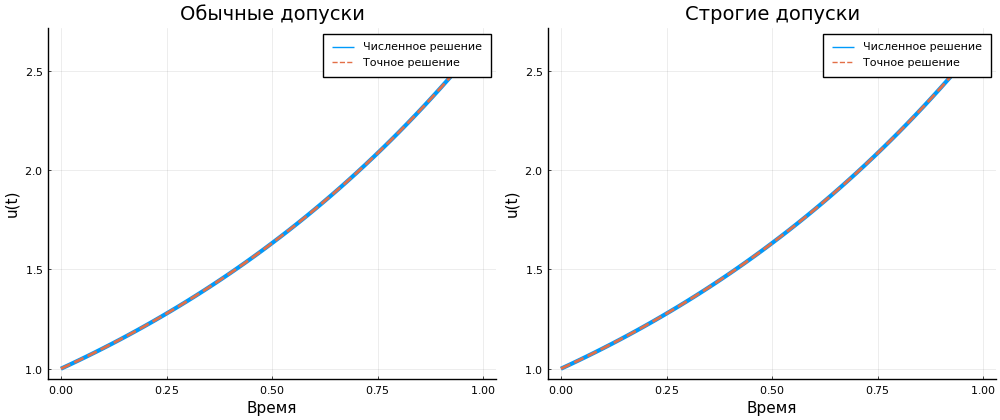

In [5]:
pyplot()

p1 = plot(sol_default.t, sol_default.u;
    title="Обычные допуски",
    xlabel="Время", ylabel="u(t)",
    label="Численное решение", linewidth=3)

plot!(p1, sol_default.t, exact_growth.(sol_default.t);
    label="Точное решение", linestyle=:dash, linewidth=2)

p2 = plot(sol_precise.t, sol_precise.u;
    title="Строгие допуски",
    xlabel="Время", ylabel="u(t)",
    label="Численное решение", linewidth=3)

plot!(p2, sol_precise.t, exact_growth.(sol_precise.t);
    label="Точное решение", linestyle=:dash, linewidth=2)

p_growth = plot(p1, p2; layout=(1, 2), size=(1000, 420))

In [6]:
savefig(p_growth, "01_exponential_growth.png")

"/home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/01_exponential_growth.png"

## 6.2.1.2. Система Лоренца 

In [7]:
function lorenz!(du, u, p, t)
    x, y, z = u
    sigma, rho, beta = p

    du[1] = sigma * (y - x)
    du[2] = x * (rho - z) - y
    du[3] = x * y - beta * z
end

prob_lorenz = ODEProblem(
    lorenz!, [1.0, 0.0, 0.0], (0.0, 100.0), (10.0, 28.0, 8/3)
)
sol_lorenz = solve(prob_lorenz, Tsit5(); abstol=1e-8, reltol=1e-8);

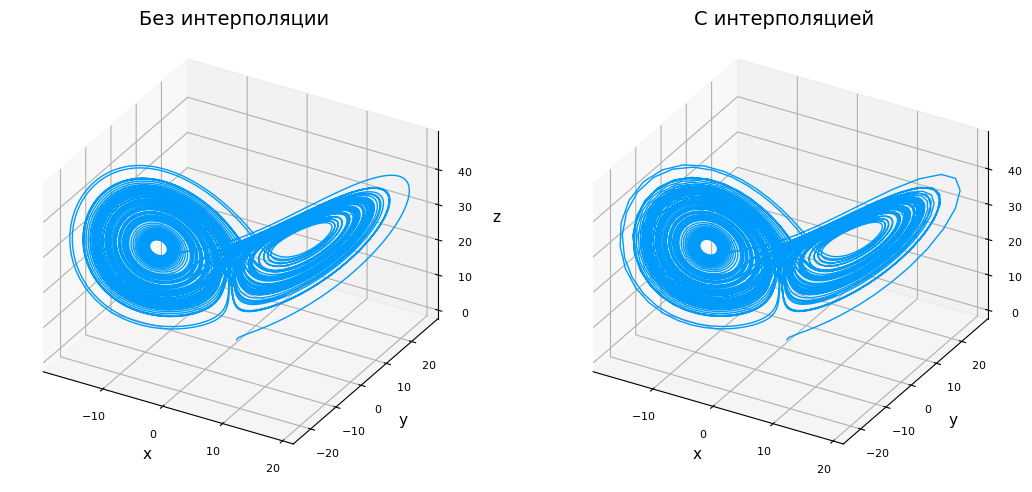

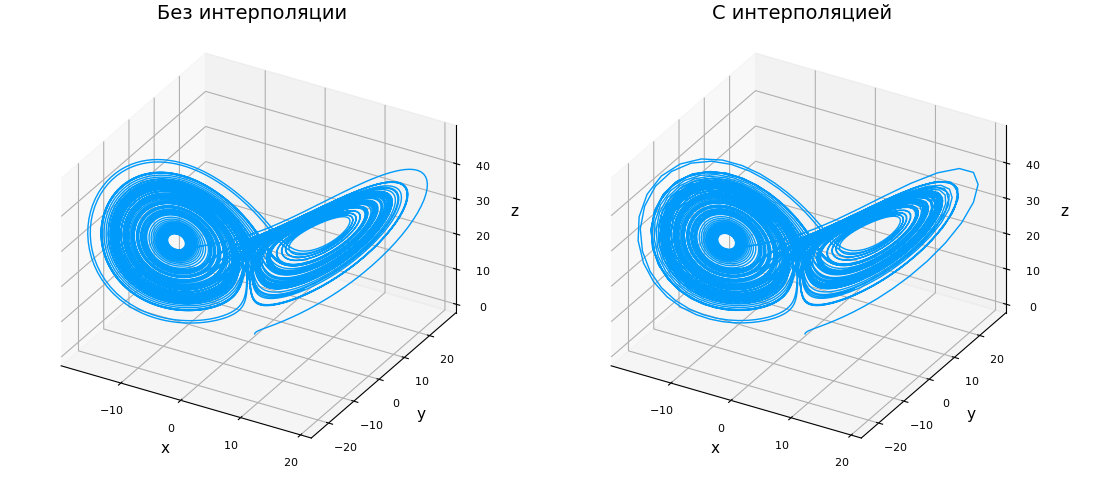

In [8]:
t_dense = range(0.0, 100.0; length=6000)
lorenz_saved = Array(sol_lorenz)
lorenz_dense = hcat(sol_lorenz.(t_dense)...)

p_saved = plot(
    lorenz_saved[1, :], lorenz_saved[2, :], lorenz_saved[3, :];
    title="Без интерполяции", xlabel="x", ylabel="y", zlabel="z",
    legend=false, linewidth=1
)

p_dense = plot(
    lorenz_dense[1, :], lorenz_dense[2, :], lorenz_dense[3, :];
    title="С интерполяцией", xlabel="x", ylabel="y", zlabel="z",
    legend=false, linewidth=1
)

p_lorenz = plot(p_saved, p_dense; layout=(1, 2), size=(1100, 480))
savefig(p_lorenz, "02_lorenz.png")
p_lorenz

## 6.2.2. Модель Лотки-Вольтерры

In [9]:
function lotka_volterra!(du, u, p, t)
    prey, predator = u
    a, b, c, d = p

    du[1] = a * prey - b * prey * predator
    du[2] = -c * predator + d * prey * predator
end

prob_lv = ODEProblem(
    lotka_volterra!, [1.0, 1.0], (0.0, 10.0), (1.5, 1.0, 3.0, 1.0)
)
sol_lv = solve(prob_lv, Tsit5(); saveat=0.02, abstol=1e-8, reltol=1e-8);

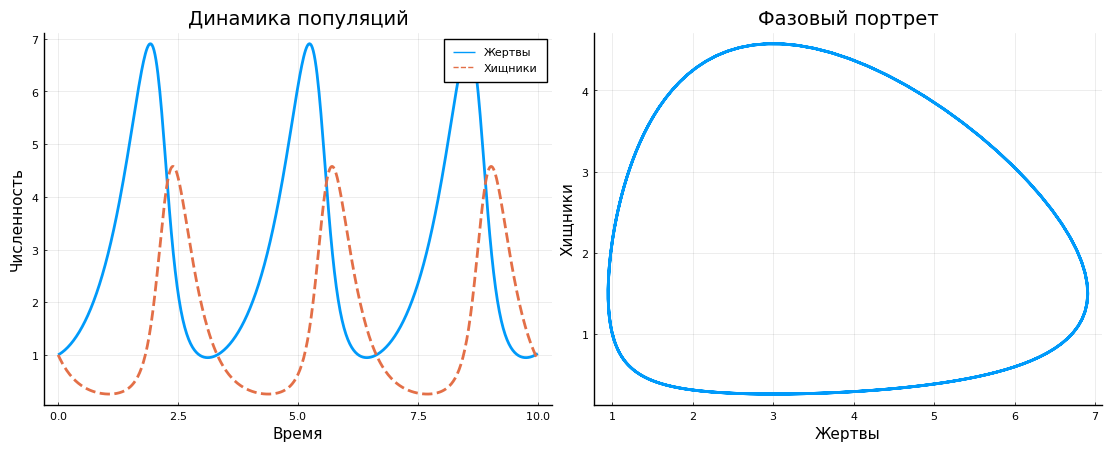

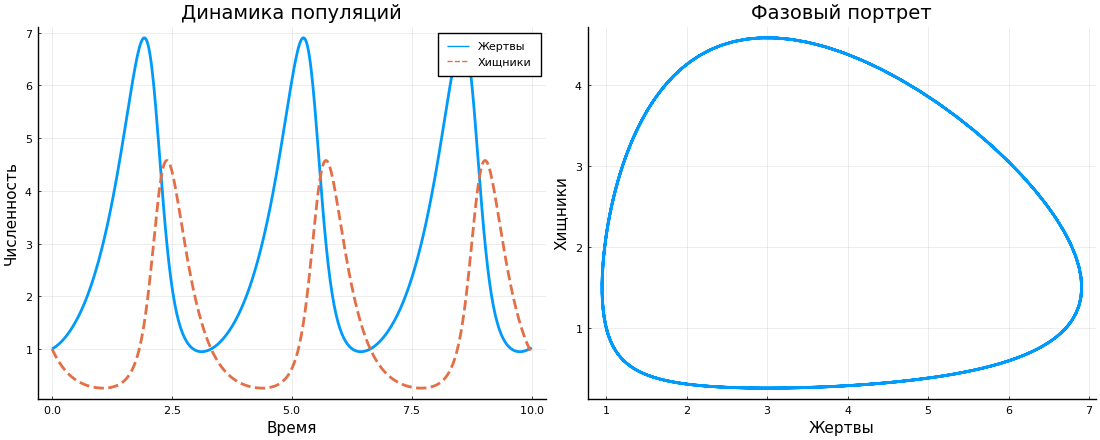

In [10]:
lv_values = Array(sol_lv)
prey = lv_values[1, :]
predators = lv_values[2, :]

p_lv_time = plot(
    sol_lv.t, prey;
    title="Динамика популяций", xlabel="Время", ylabel="Численность",
    label="Жертвы", linewidth=2
)
plot!(p_lv_time, sol_lv.t, predators;
      label="Хищники", linestyle=:dash, linewidth=2)

p_lv_phase = plot(
    prey, predators;
    title="Фазовый портрет", xlabel="Жертвы", ylabel="Хищники",
    legend=false, linewidth=2
)

p_lv = plot(p_lv_time, p_lv_phase; layout=(1, 2), size=(1100, 440))
savefig(p_lv, "03_lotka_volterra.png")
p_lv

## 6.4.1. Модель Мальтуса

Начальная чесленность составляет 10 особей. Коэффициент рождаемости равен 0,3, а коэффициент сметрности равен 0,1. Разность 0,2 положительна, поэтому популяция растёт. Модель не учитывает ограниченность ресурсов.

Численность при t = 20: 545.98


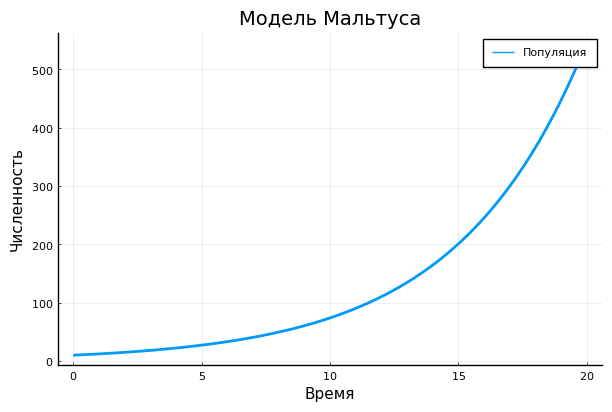

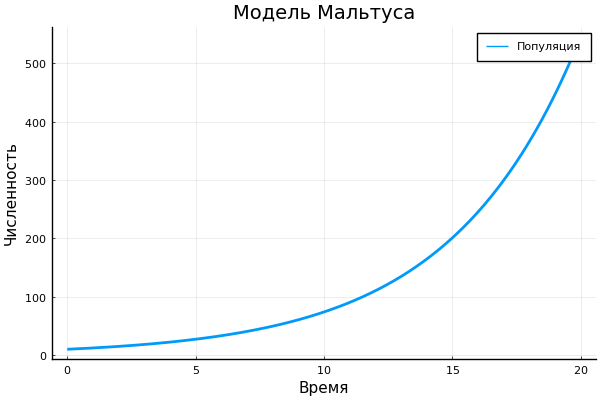

In [11]:
malthus(x, a, t) = a * x

b = 0.3
c = 0.1
a = b - c

prob_malthus = ODEProblem(malthus, 10.0, (0.0, 20.0), a)
sol_malthus = solve(prob_malthus, Tsit5(); saveat=0.1,
                    abstol=1e-8, reltol=1e-8)

p_malthus = plot(sol_malthus.t, sol_malthus.u;
    title="Модель Мальтуса", xlabel="Время", ylabel="Численность",
    label="Популяция", linewidth=2)

savefig(p_malthus, "04_malthus.png")
println("Численность при t = 20: ", round(sol_malthus.u[end]; digits=2))
p_malthus

## 6.4.2. Логистическая модель роста

Начальную численность и коэффициент роста берём такими же, как в модели
Мальтуса. Ёмкость среды задаём равной 100 особям. Начальная численность
ниже этого предела, поэтому популяция растёт, но по мере приближения
к пределу рост замедляется.

Численность при t = 20: 85.85


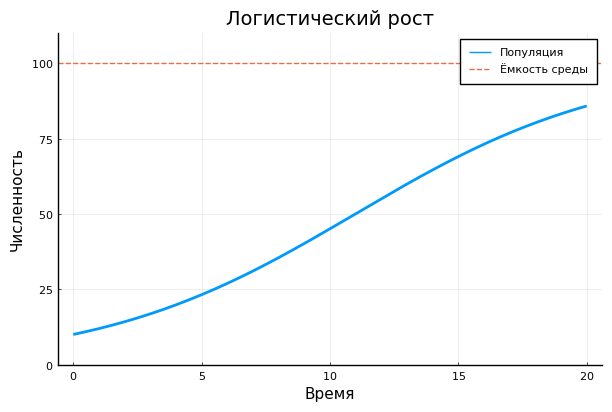

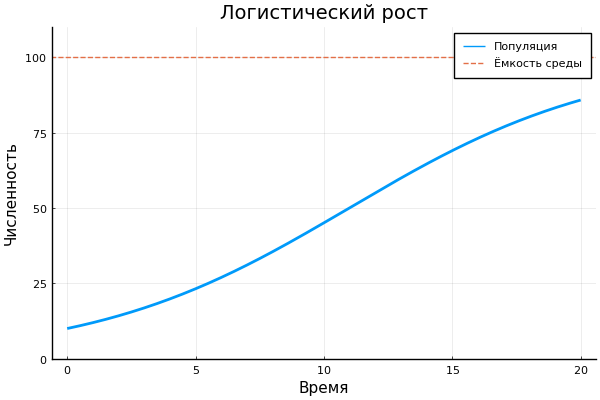

In [12]:
function logistic(x, p, t)
    r, K = p
    return r * x * (1 - x / K)
end

K = 100.0
prob_logistic = ODEProblem(logistic, 10.0, (0.0, 20.0), (a, K))
sol_logistic = solve(prob_logistic, Tsit5(); saveat=0.1,
                     abstol=1e-8, reltol=1e-8)

p_logistic = plot(sol_logistic.t, sol_logistic.u;
    title="Логистический рост", xlabel="Время", ylabel="Численность",
    label="Популяция", linewidth=2, ylims=(0, 110))

hline!(p_logistic, [K]; label="Ёмкость среды", linestyle=:dash)

savefig(p_logistic, "05_logistic.png")
println("Численность при t = 20: ", round(sol_logistic.u[end]; digits=2))
p_logistic

In [13]:
function animate_population(sol, title_text, filename; capacity=nothing)
    ymax = 1.1 * maximum(sol.u)
    if capacity !== nothing
        ymax = max(ymax, 1.1 * capacity)
    end

    frames = @animate for j in 1:5:length(sol.t)
        p = plot(sol.t[1:j], sol.u[1:j];
            title=title_text, xlabel="Время", ylabel="Численность",
            xlims=(sol.t[1], sol.t[end]), ylims=(0, ymax),
            label="Популяция", linewidth=2)

        if capacity !== nothing
            hline!(p, [capacity]; label="Ёмкость среды", linestyle=:dash)
        end
    end

    gif(frames, filename; fps=10)
end

animate_population (generic function with 1 method)

[ Info: Saved animation to /home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/04_malthus.gif


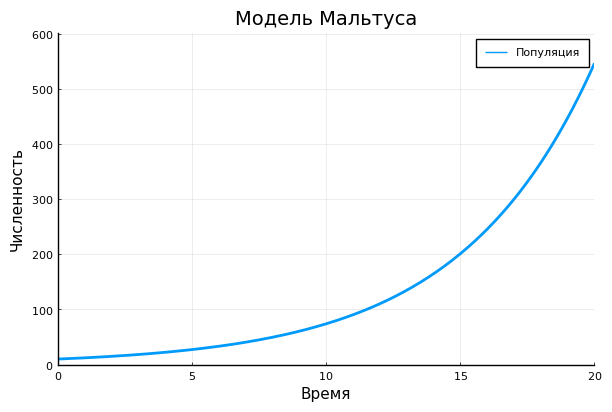

Plots.AnimatedGif("/home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/04_malthus.gif")
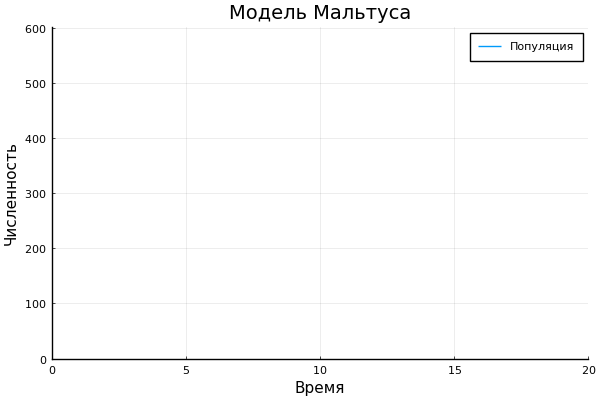

In [14]:
animate_population(sol_malthus, "Модель Мальтуса", "04_malthus.gif")

[ Info: Saved animation to /home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/05_logistic.gif


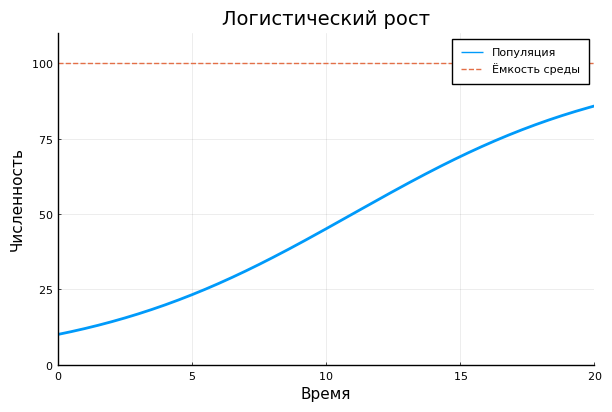

Plots.AnimatedGif("/home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/05_logistic.gif")
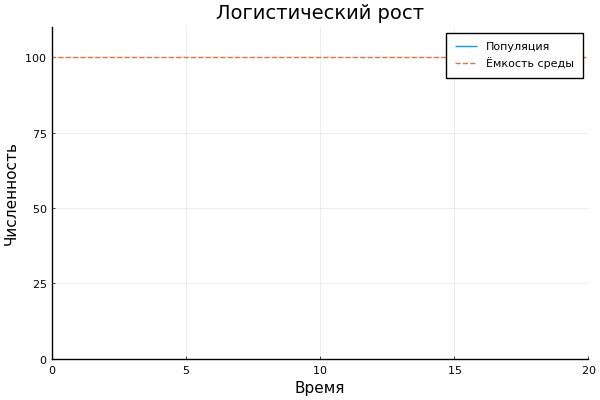

In [15]:
animate_population(sol_logistic, "Логистический рост", "05_logistic.gif"; capacity=K)

## 6.4.3. Модель SIR

In [16]:
function sir!(du, u, p, t)
    S, I, R = u
    beta, gamma = p

    new_infections = beta * S * I
    removals = gamma * I

    du[1] = -new_infections
    du[2] = new_infections - removals
    du[3] = removals
end

beta_sir = 0.6
gamma_sir = 0.2
tspan_sir = (0.0, 60.0)

prob_sir = ODEProblem(
    sir!, [0.99, 0.01, 0.0], tspan_sir, (beta_sir, gamma_sir)
)
sol_sir = solve(prob_sir, Tsit5(); saveat=0.2,
                abstol=1e-8, reltol=1e-8)

sir_values = Array(sol_sir);

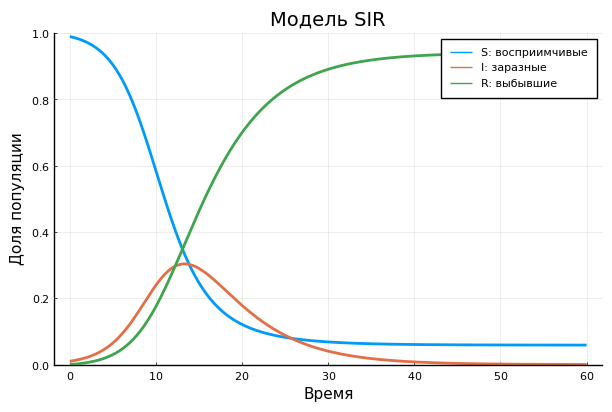

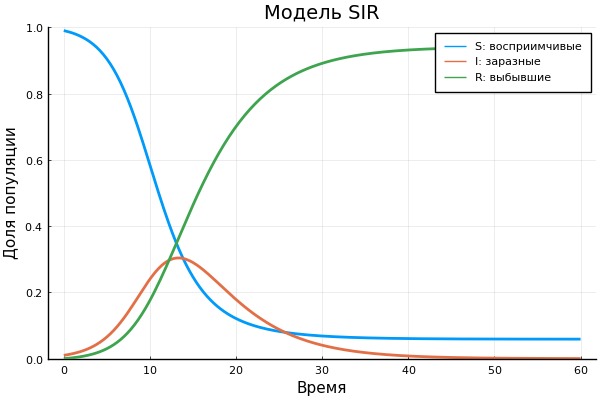

In [17]:
p_sir = plot(sol_sir.t, sir_values';
    title="Модель SIR", xlabel="Время", ylabel="Доля популяции",
    label=["S: восприимчивые" "I: заразные" "R: выбывшие"],
    linewidth=2, ylims=(0, 1))

savefig(p_sir, "06_sir.png")
p_sir

[ Info: Saved animation to /home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/06_sir.gif


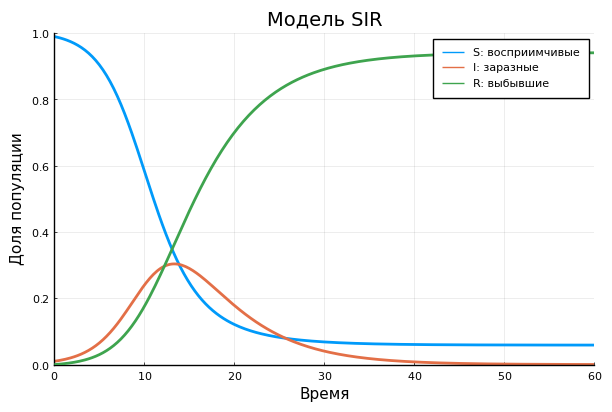

Plots.AnimatedGif("/home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/06_sir.gif")
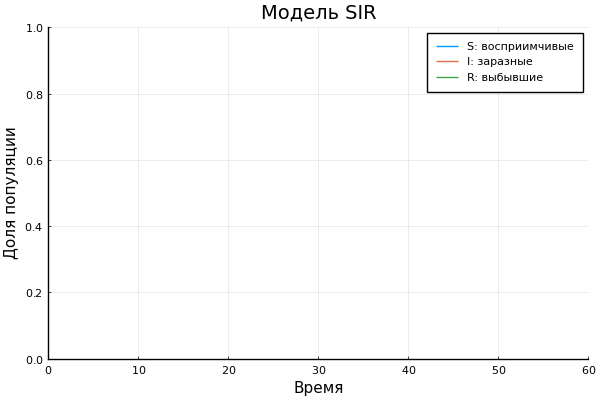

In [18]:
sir_frames = @animate for j in 1:6:length(sol_sir.t)
    plot(sol_sir.t[1:j], sir_values[:, 1:j]';
        title="Модель SIR", xlabel="Время", ylabel="Доля популяции",
        label=["S: восприимчивые" "I: заразные" "R: выбывшие"],
        linewidth=2, xlims=tspan_sir, ylims=(0, 1))
end

gif(sir_frames, "06_sir.gif"; fps=10)

## 6.4.4. Модель SIR и сравнение с SIR

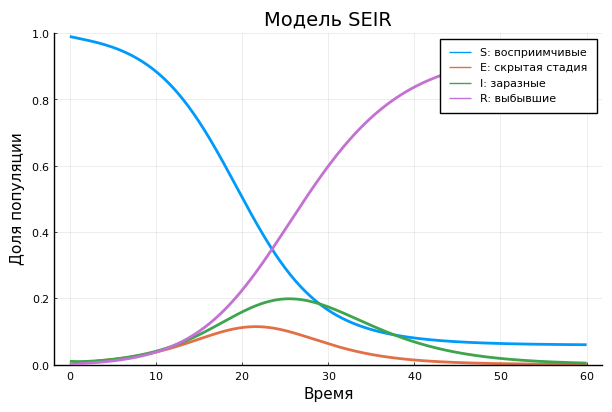

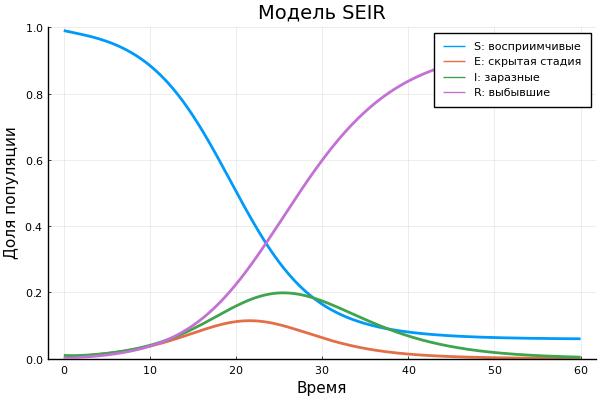

In [19]:
function seir!(du, u, p, t)
    S, E, I, R = u
    beta, delta, gamma = p

    new_infections = beta * S * I
    become_infectious = delta * E
    removals = gamma * I

    du[1] = -new_infections
    du[2] = new_infections - become_infectious
    du[3] = become_infectious - removals
    du[4] = removals
end

delta_seir = 0.4

prob_seir = ODEProblem(
    seir!, [0.99, 0.0, 0.01, 0.0], tspan_sir,
    (beta_sir, delta_seir, gamma_sir)
)
sol_seir = solve(prob_seir, Tsit5(); saveat=0.2,
                 abstol=1e-8, reltol=1e-8)

seir_values = Array(sol_seir);

p_seir = plot(sol_seir.t, seir_values';
    title="Модель SEIR", xlabel="Время", ylabel="Доля популяции",
    label=["S: восприимчивые" "E: скрытая стадия" "I: заразные" "R: выбывшие"],
    linewidth=2, ylims=(0, 1))

savefig(p_seir, "07_seir.png")
p_seir

SIR: пик 30.38% при t = 13.4
SEIR: пик 19.86% при t = 25.4
Отклонение суммы долей от 1 в SIR: 3.3306690738754696e-16
Отклонение суммы долей от 1 в SEIR: 4.440892098500626e-16


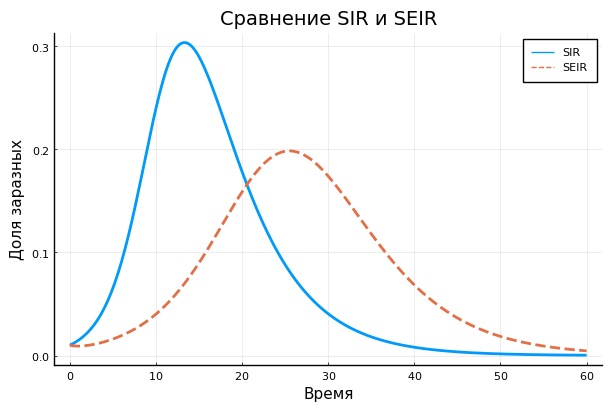

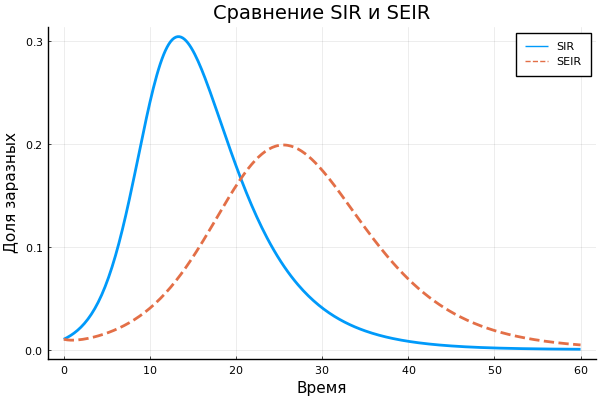

In [20]:
I_sir = sir_values[2, :]
I_seir = seir_values[3, :]

p_compare = plot(sol_sir.t, I_sir;
    title="Сравнение SIR и SEIR", xlabel="Время",
    ylabel="Доля заразных", label="SIR", linewidth=2)

plot!(p_compare, sol_seir.t, I_seir;
    label="SEIR", linestyle=:dash, linewidth=2)

savefig(p_compare, "08_sir_seir_comparison.png")

j_sir = argmax(I_sir)
j_seir = argmax(I_seir)

println("SIR: пик ", round(100 * I_sir[j_sir]; digits=2),
        "% при t = ", sol_sir.t[j_sir])
println("SEIR: пик ", round(100 * I_seir[j_seir]; digits=2),
        "% при t = ", sol_seir.t[j_seir])

println("Отклонение суммы долей от 1 в SIR: ",
        maximum(abs.(sum(sir_values; dims=1) .- 1)))
println("Отклонение суммы долей от 1 в SEIR: ",
        maximum(abs.(sum(seir_values; dims=1) .- 1)))

p_compare

## 6.4.5. Дискретная модель Лотки–Вольтерры

В точке равновесия обе численности сохраняются от шага к шагу:

$$
x=2x(1-x)-xy,\qquad y=-y+5xy.
$$

Переносим всё в одну сторону:

$$
x(1-2x-y)=0,\qquad y(5x-2)=0.
$$

Если $y=0$, получаем равновесия $(0,0)$ и $(0.5,0)$.
Если $y>0$, то $x=0.4$, а из первого уравнения получаем $y=0.2$.
Точка сосуществования двух популяций равна $(0.4,0.2)$.

sys:1: UserWarning: No data for colormapping provided via 'c'. Parameters 'vmin', 'vmax' will be ignored


Последняя точка: [0.4, 0.20001]


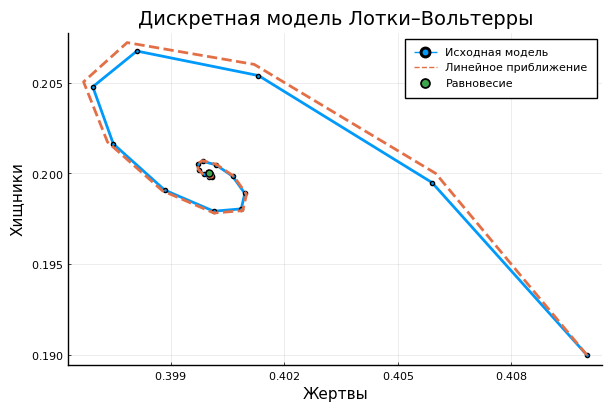

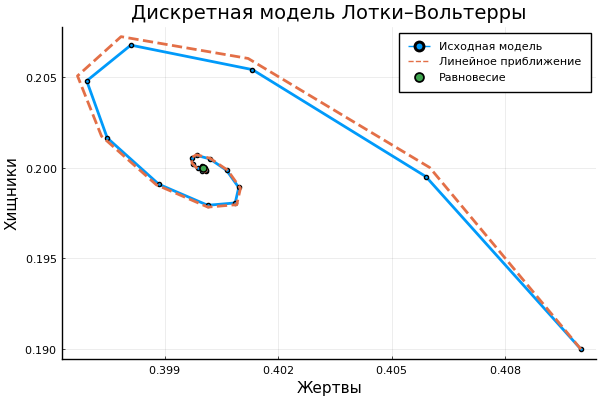

In [21]:
n_steps = 30
equilibrium = [0.4, 0.2]
initial = [0.41, 0.19]

# Исходная модель: каждый столбец содержит x и y на одном шаге
trajectory = zeros(2, n_steps + 1)
trajectory[:, 1] = initial

for j in 1:n_steps
    x, y = trajectory[:, j]
    trajectory[1, j + 1] = 2 * x * (1 - x) - x * y
    trajectory[2, j + 1] = -y + 5 * x * y
end

# Матрица производных в точке равновесия
J = [0.2 -0.4; 1.0 1.0]
delta_initial = initial - equilibrium

linear_trajectory = hcat(
    [equilibrium + J^n * delta_initial for n in 0:n_steps]...
)

p_discrete = plot(
    trajectory[1, :], trajectory[2, :];
    title="Дискретная модель Лотки–Вольтерры",
    xlabel="Жертвы", ylabel="Хищники",
    label="Исходная модель", linewidth=2, marker=:circle, markersize=3
)

plot!(p_discrete, linear_trajectory[1, :], linear_trajectory[2, :];
      label="Линейное приближение", linestyle=:dash, linewidth=2)
scatter!(p_discrete, [0.4], [0.2]; label="Равновесие", markersize=5)

savefig(p_discrete, "09_discrete_lotka_volterra.png")
println("Последняя точка: ", round.(trajectory[:, end]; digits=5))
p_discrete

## 6.4.6. Модель отбора на основе конкурентных отношений

Обе популяции имеют одинаковый коэффициент роста $\alpha=0.4$.
Силу конкуренции задаём коэффициентом $\beta=0.04$.
Начальные численности равны 12 и 8. Разные начальные значения
позволяют увидеть, как меняется начальное преимущество первой популяции.

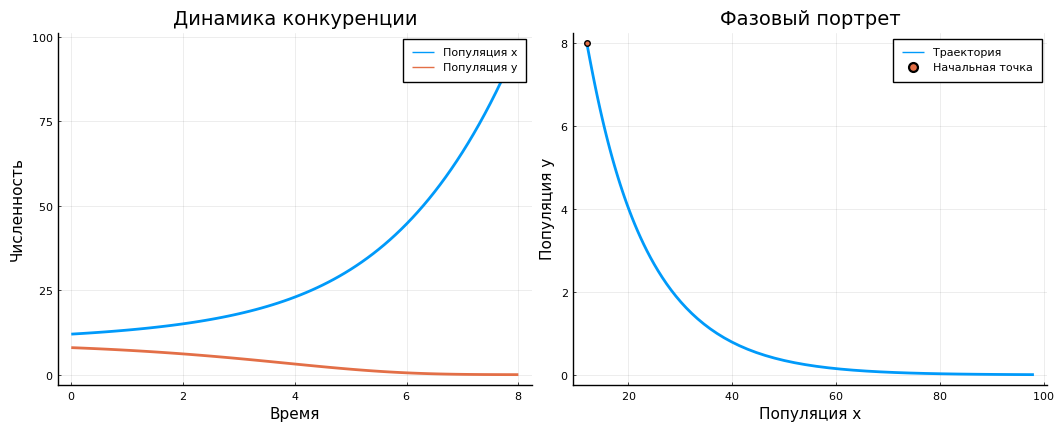

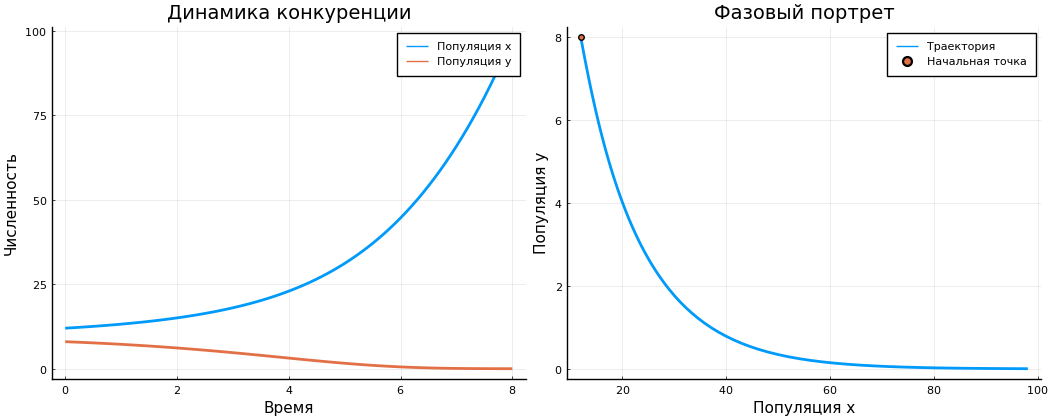

In [22]:
function competition!(du, u, p, t)
    x, y = u
    alpha, beta = p

    loss = beta * x * y
    du[1] = alpha * x - loss
    du[2] = alpha * y - loss
end

tspan_comp = (0.0, 8.0)
prob_comp = ODEProblem(
    competition!, [12.0, 8.0], tspan_comp, (0.4, 0.04)
)
sol_comp = solve(prob_comp, Tsit5(); saveat=0.1,
                 abstol=1e-8, reltol=1e-8)

comp_values = Array(sol_comp)
comp_x = comp_values[1, :]
comp_y = comp_values[2, :]

p_comp_time = plot(
    sol_comp.t, comp_values';
    title="Динамика конкуренции", xlabel="Время", ylabel="Численность",
    label=["Популяция x" "Популяция y"], linewidth=2
)

p_comp_phase = plot(
    comp_x, comp_y;
    title="Фазовый портрет", xlabel="Популяция x", ylabel="Популяция y",
    label="Траектория", linewidth=2
)
scatter!(p_comp_phase, [comp_x[1]], [comp_y[1]]; label="Начальная точка")

p_comp = plot(p_comp_time, p_comp_phase; layout=(1, 2), size=(1050, 420))
savefig(p_comp, "10_competition.png")
p_comp

[ Info: Saved animation to /home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/10_competition.gif


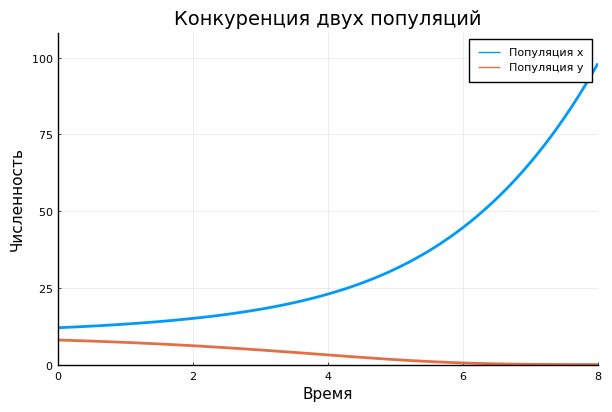

Plots.AnimatedGif("/home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/10_competition.gif")
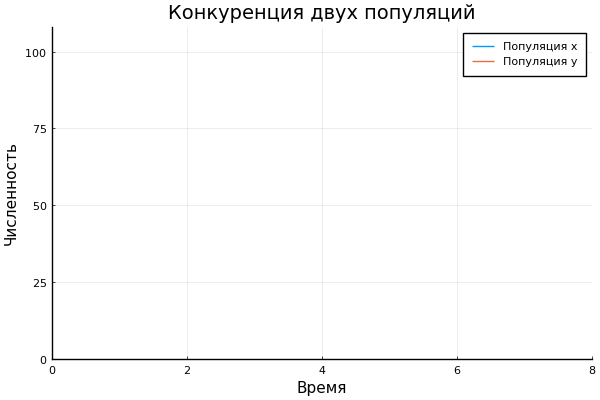

In [23]:
comp_ymax = 1.1 * maximum(comp_values)

competition_frames = @animate for j in 1:2:length(sol_comp.t)
    plot(sol_comp.t[1:j], comp_values[:, 1:j]';
        title="Конкуренция двух популяций",
        xlabel="Время", ylabel="Численность",
        label=["Популяция x" "Популяция y"], linewidth=2,
        xlims=tspan_comp, ylims=(0, comp_ymax))
end

gif(competition_frames, "10_competition.gif"; fps=10)

## 6.4.7. Консервативный гармонический осциллятор
## 6.4.8. Гармонический осциллятор с затуханием

Начальное смещение $x(0)=1$, начальная скорость $v(0)=0$.
Это означает, что тело сначала отклонили от положения равновесия
и отпустили без толчка. В обеих моделях собственная частота $\omega_0=1$.
В первой модели $\gamma=0$, во второй $\gamma=0.2$.
Поскольку $0<\gamma<\omega_0$, во второй модели сохраняются колебания,
но их амплитуда уменьшается.

Уравнение второго порядка записываем как два уравнения первого порядка:

$$
x'=v,\qquad v'=-\omega_0^2 x-2\gamma v.
$$

In [24]:
function oscillator!(du, u, p, t)
    x, v = u
    omega, gamma = p

    du[1] = v
    du[2] = -omega^2 * x - 2 * gamma * v
end

tspan_osc = (0.0, 20.0)

prob_free = ODEProblem(
    oscillator!, [1.0, 0.0], tspan_osc, (1.0, 0.0)
)
prob_damped = ODEProblem(
    oscillator!, [1.0, 0.0], tspan_osc, (1.0, 0.2)
)

sol_free = solve(prob_free, Tsit5(); saveat=0.1,
                 abstol=1e-8, reltol=1e-8)
sol_damped = solve(prob_damped, Tsit5(); saveat=0.1,
                   abstol=1e-8, reltol=1e-8);

In [25]:
function show_oscillator(sol, title_text, filename)
    values = Array(sol)
    x = values[1, :]
    v = values[2, :]

    p_time = plot(sol.t, x;
        title=title_text, xlabel="Время", ylabel="Смещение",
        label="x(t)", linewidth=2, ylims=(-1.1, 1.1))

    p_phase = plot(x, v;
        title="Фазовый портрет", xlabel="Смещение x", ylabel="Скорость v",
        legend=false, linewidth=2, aspect_ratio=:equal,
        xlims=(-1.1, 1.1), ylims=(-1.1, 1.1))

    p = plot(p_time, p_phase; layout=(1, 2), size=(1050, 440))
    savefig(p, filename)
    return p
end

show_oscillator (generic function with 1 method)

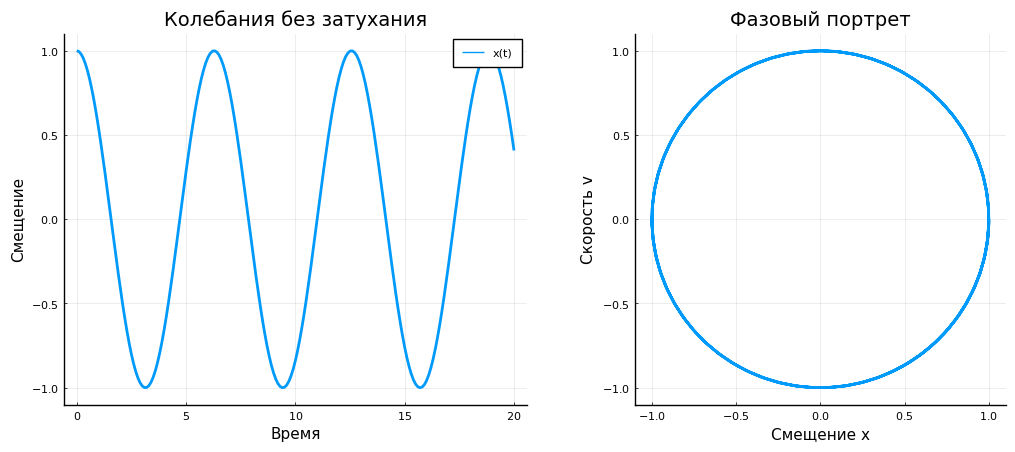

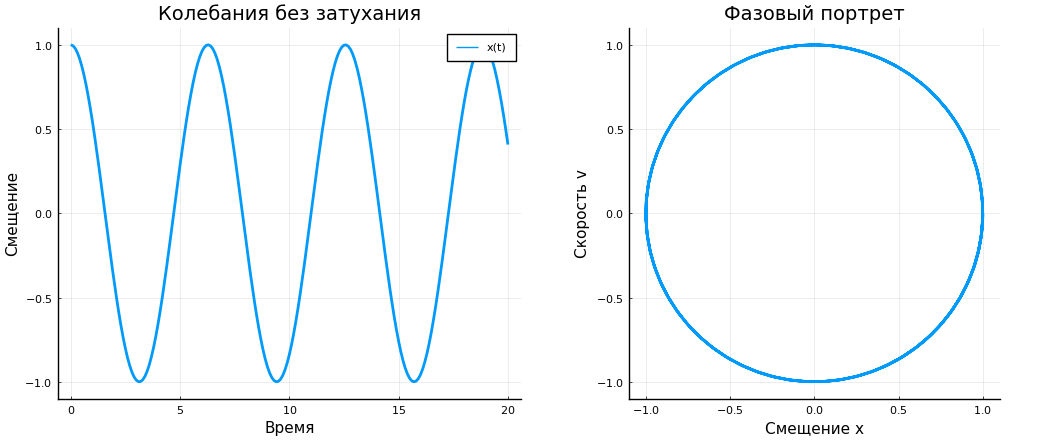

In [26]:
show_oscillator(sol_free, "Колебания без затухания", "11_oscillator_free.png")

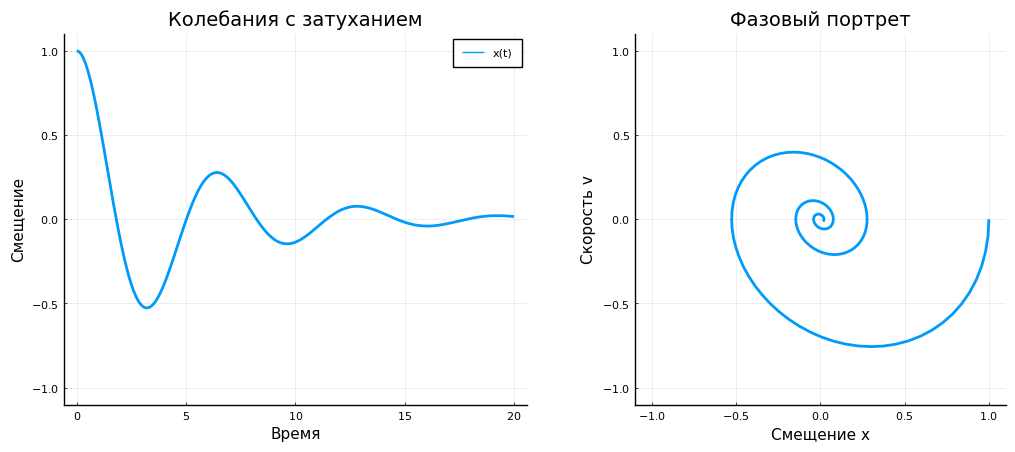

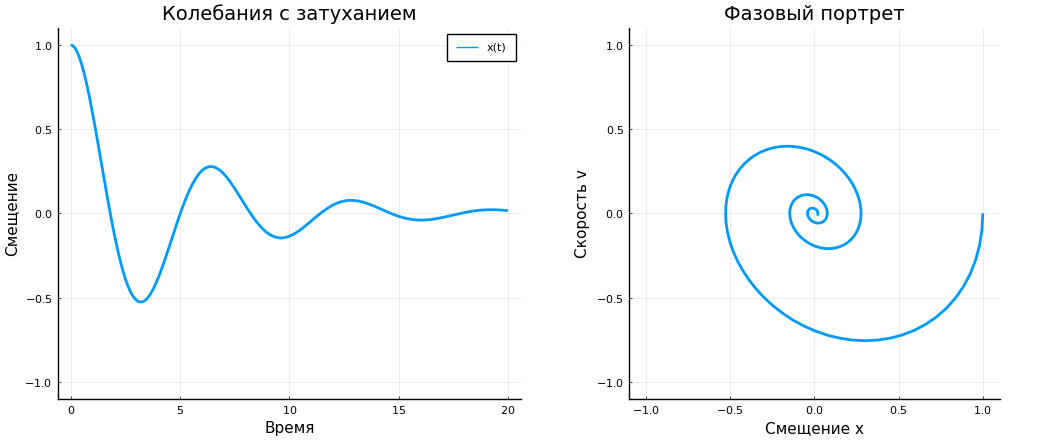

In [27]:
show_oscillator(sol_damped, "Колебания с затуханием", "12_oscillator_damped.png")

In [28]:
energy_free = [sum(abs2, state) / 2 for state in sol_free.u]
energy_damped = [sum(abs2, state) / 2 for state in sol_damped.u]

println("Без затухания: ", energy_free[1], " → ", energy_free[end])
println("С затуханием: ", energy_damped[1], " → ", energy_damped[end])

Без затухания: 0.5 → 0.4999999933968116
С затуханием: 0.5 → 0.0002083087277591548


In [29]:
function animate_oscillator(sol, title_text, filename)
    x = Array(sol)[1, :]

    frames = @animate for j in 1:4:length(sol.t)
        p = plot(sol.t[1:j], x[1:j];
            title=title_text, xlabel="Время", ylabel="Смещение",
            label="x(t)", linewidth=2, size=(700, 400),
            xlims=(sol.t[1], sol.t[end]), ylims=(-1.1, 1.1))

        scatter!(p, [sol.t[j]], [x[j]];
                 color=:red, markersize=4, label="")
    end

    gif(frames, filename; fps=10)
end

animate_oscillator (generic function with 1 method)

[ Info: Saved animation to /home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/11_oscillator_free.gif


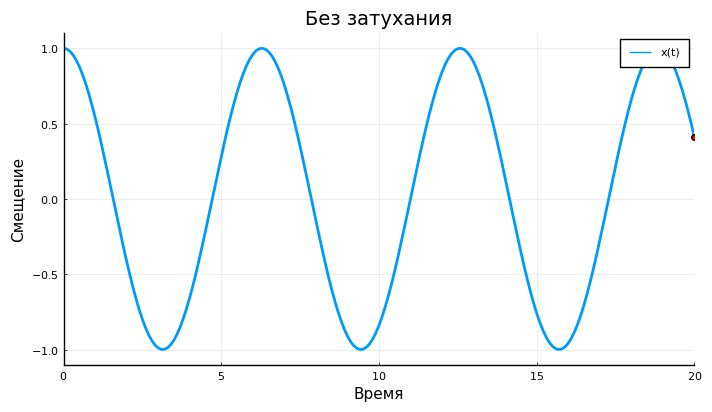

Plots.AnimatedGif("/home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/11_oscillator_free.gif")
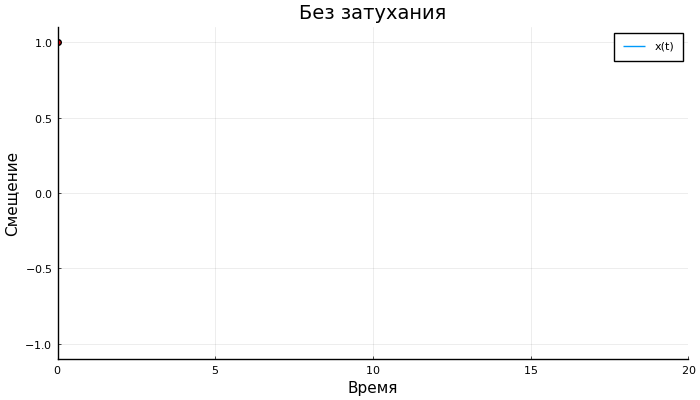

In [30]:
animate_oscillator(sol_free, "Без затухания", "11_oscillator_free.gif")

[ Info: Saved animation to /home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/12_oscillator_damped.gif


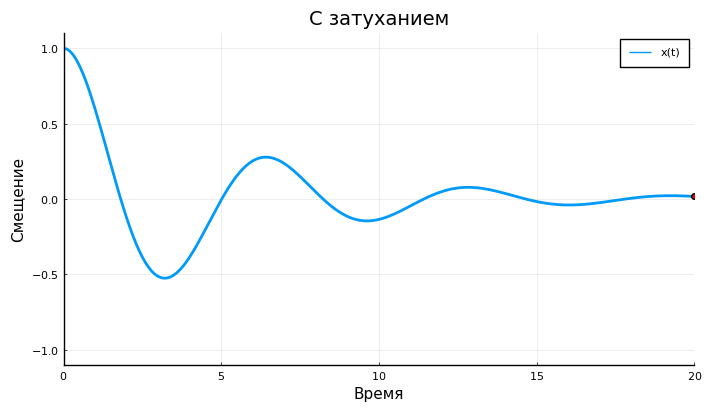

Plots.AnimatedGif("/home/umedn/work/study/2026-2/2026-2==computer-practice/2026-2--study--computer-practice/labs/lab06/project/12_oscillator_damped.gif")
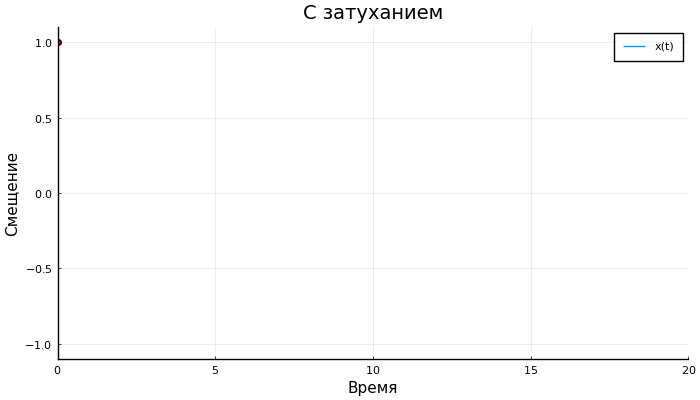

In [31]:
animate_oscillator(sol_damped, "С затуханием", "12_oscillator_damped.gif")